# Кейс № 8 — подбор гиперпараметров (пункт 5)
**Проектный практикум · команда 13**

**Задача:** оптимизировать регрессионную модель для прогноза числа арендованных велосипедов за час.

Это **первый самостоятельный шаблон**: пока модели других участников не добавлены в `main`, используем `RandomForestRegressor` как пример. Когда команда определит 1–2 лучшие модели, заменим `model` и `param_distributions` на их варианты.

**Правила эксперимента:**
- только хронологический `train → validation → test`, без `shuffle`;
- `TimeSeriesSplit` внутри **train** для подбора гиперпараметров;
- `validation` — для сравнения исходной и настроенной моделей;
- **test не используем** в этом ноутбуке;
- категориальные признаки преобразуем внутри `Pipeline`, чтобы избежать утечки информации.

**Важно:** параметры сплита и политика обработки нерабочих часов ниже временные — их требуется согласовать с командой до итоговых экспериментов.

## 1. Импорты и настройки

`random_state=42` фиксирует случайность **обучения модели и поиска**. Хронологическое разбиение само по себе детерминированное и не требует `random_state`.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
TRAIN_FRACTION = 0.70  # временно, до согласования с командой
VALID_FRACTION = 0.15  # оставшиеся 15% — тест
KEEP_NON_FUNCTIONING = True  # временно: нерабочие часы остаются в данных

# Если CSV уже скачан, можно указать путь вручную, например:
# LOCAL_CSV = Path("data/raw/SeoulBikeData.csv")
LOCAL_CSV = None

pd.set_option("display.max_columns", 30)

## 2. Загрузка фиксированной версии данных

В `eda.ipynb` Александра датасет загружается через `kagglehub` из `joebeachcapital/seoul-bike-sharing`. Здесь указан **version 1**. Если локального файла нет, код попробует скачать эту версию.

Сохраняем SHA-256 файла — это цифровой отпечаток, который поможет проверить, что все участники используют одинаковые данные.

In [2]:
def project_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd.parent):
        if (candidate / "pyproject.toml").exists():
            return candidate
    return cwd

root = project_root()
if LOCAL_CSV is not None:
    csv_path = Path(LOCAL_CSV).expanduser().resolve()
else:
    local_candidates = [
        root / "data" / "raw" / "SeoulBikeData.csv",
        root / "files" / "SeoulBikeData.csv",
    ]
    csv_path = next((f for f in local_candidates if f.is_file()), None)
    if csv_path is None:
        import kagglehub
        downloaded_path = kagglehub.dataset_download(
            "joebeachcapital/seoul-bike-sharing/versions/1"
        )
        matches = list(Path(downloaded_path).rglob("SeoulBikeData.csv"))
        if not matches:
            raise FileNotFoundError("SeoulBikeData.csv не найден в каталоге Kaggle")
        csv_path = matches[0]

if not csv_path.is_file():
    raise FileNotFoundError(f"Датасет не найден: {csv_path}")

file_hash = hashlib.sha256(csv_path.read_bytes()).hexdigest()
print("CSV:", csv_path)
print("SHA-256:", file_hash)

try:
    df = pd.read_csv(csv_path, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(csv_path, encoding="cp1252")
print("Размер:", df.shape)
assert len(df) == 8760, "Ожидали 8760 почасовых наблюдений — проверьте версию CSV"

CSV: /kaggle/input/datasets/joebeachcapital/seoul-bike-sharing/SeoulBikeData.csv
SHA-256: 373339b71a8935d69e9af0abf26a70744632119862eeb3919efb389a7b749c60
Размер: (8760, 14)


## 3. Подготовка временной оси и признаков

Это **минимальная временная реализация**, чтобы можно было проверить пункт 5 до готовности общего кода команды. Позже заменим на подготовку данных Андрея, сохранив одинаковый формат `X_train`, `y_train`, `X_val`, `y_val`.

Мы **не используем `Rented Bike Count` для создания признаков**. `Date` переводим в день недели/месяц, а время объединяем в `timestamp` только для сортировки.

In [3]:
required_columns = {
    "Date", "Hour", "Rented Bike Count", "Seasons", "Holiday", "Functioning Day"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"В CSV отсутствуют колонки: {missing_columns}")

frame = df.copy()
frame["Date"] = pd.to_datetime(frame["Date"], format="%d/%m/%Y")
frame["timestamp"] = frame["Date"] + pd.to_timedelta(frame["Hour"], unit="h")
frame = frame.sort_values("timestamp").reset_index(drop=True)

if frame["timestamp"].duplicated().any():
    raise ValueError("Есть повторяющиеся дата + час")

frame["day_of_week"] = frame["Date"].dt.dayofweek
frame["month"] = frame["Date"].dt.month
frame["is_weekend"] = (frame["day_of_week"] >= 5).astype(int)
frame["hour_sin"] = np.sin(2 * np.pi * frame["Hour"] / 24)
frame["hour_cos"] = np.cos(2 * np.pi * frame["Hour"] / 24)

print("Период:", frame["timestamp"].min(), "—", frame["timestamp"].max())
print("Нерабочих часов:", (frame["Functioning Day"] == "No").sum())

Период: 2017-12-01 00:00:00 — 2018-11-30 23:00:00
Нерабочих часов: 295


## 4. Один общий хронологический сплит

Делим **по индексам отсортированного по времени датасета**. У модели нет доступа к информации из будущих периодов на этапе обучения.

Политика `KEEP_NON_FUNCTIONING` применяется **после разбиения**, чтобы при изменении политики временные границы оставались одинаковыми. Пока по умолчанию сохраняем все часы. Это техническое допущение, **не принятое командой решение**.

In [4]:
n = len(frame)
train_end = int(n * TRAIN_FRACTION)
val_end = train_end + int(n * VALID_FRACTION)
assert 0 < train_end < val_end < n

train_data = frame.iloc[:train_end].copy()
val_data = frame.iloc[train_end:val_end].copy()
test_data = frame.iloc[val_end:].copy()  # НЕ используем для тюнинга

if not KEEP_NON_FUNCTIONING:
    train_data = train_data.loc[train_data["Functioning Day"] == "Yes"].copy()
    val_data = val_data.loc[val_data["Functioning Day"] == "Yes"].copy()
    # test_data оставляем нетронутой до итоговой проверки команды

print("TRAIN:", len(train_data), train_data["timestamp"].min(), train_data["timestamp"].max())
print("VALID:", len(val_data), val_data["timestamp"].min(), val_data["timestamp"].max())
print("TEST: ", len(test_data), "наблюдений (заморожена; метрики не считаем)")
assert train_data["timestamp"].max() < val_data["timestamp"].min()
assert val_data["timestamp"].max() < test_data["timestamp"].min()

TRAIN: 6132 2017-12-01 00:00:00 2018-08-13 11:00:00
VALID: 1314 2018-08-13 12:00:00 2018-10-07 05:00:00
TEST:  1314 наблюдений (заморожена; метрики не считаем)


## 5. Отбор признаков и конвейер обработки

Все преобразования категорий (`OneHotEncoder`) обучаются **только на train** внутри `Pipeline`. Деревьям не требуется масштабирование числовых признаков.

Для Ridge и других линейных моделей будет нужен **другой** препроцессор со `StandardScaler`, согласованный с ответственным за эти модели.

In [5]:
target_column = "Rented Bike Count"
cat_cols = ["Seasons", "Holiday", "Functioning Day"]
num_cols = [
    "Hour", "Temperature(°C)", "Humidity(%)", "Wind speed (m/s)",
    "Visibility (10m)", "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)", "Rainfall(mm)", "Snowfall (cm)",
    "day_of_week", "month", "is_weekend", "hour_sin", "hour_cos",
]
feature_cols = num_cols + cat_cols
missing_features = set(feature_cols) - set(frame.columns)
if missing_features:
    raise ValueError(f"Не найдены признаки: {missing_features}")

X_train = train_data[feature_cols]
y_train = train_data[target_column]
X_val = val_data[feature_cols]
y_val = val_data[target_column]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop",
)

print("Признаки:", len(feature_cols))
print("X_train:", X_train.shape, "X_val:", X_val.shape)

Признаки: 17
X_train: (6132, 17) X_val: (1314, 17)


## 6. Функция расчёта метрик

`RMSE` — корень из **среднего квадрата** ошибки: сильнее штрафует большие промахи. `MAE` — средняя абсолютная ошибка. `R²` отражает качество относительно константного прогноза. Чем ниже RMSE/MAE — тем лучше.

In [19]:
def regression_metrics(y_true, y_pred) -> dict:
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }

def show_metrics(label: str, metrics: dict) -> None:
    print(f"{label}: RMSE={metrics['RMSE']:.2f}, "
          f"MAE={metrics['MAE']:.2f}, R²={metrics['R2']:.3f}")

## 7. Исходная модель — точка отсчёта

Это временный пример. В дальнейшем используем именно **лучшую модель от участника, отвечающего за ансамбли**, сохранив её настройки и совместимый `Pipeline`.

Сейчас для демонстрации берём `RandomForestRegressor` из `scikit-learn`.

In [22]:
base_model = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

base_model.fit(X_train, y_train)
base_val_pred = np.maximum(base_model.predict(X_val), 0)
base_metrics = regression_metrics(y_val, base_val_pred)
show_metrics("Исходная модель (валидация)", base_metrics)

Исходная модель (валидация): RMSE=376.00, MAE=233.71, R²=0.723


## 8. TimeSeriesSplit: правильная кросс-валидация

Это несколько проверок модели, в которых каждый раз обучение происходит **раньше по времени**, чем проверка. Делается **только на train**.

`gap=24` исключает 24 часа между обучающей и проверочной частями каждого фолда. Это консервативная защита от соседства наблюдений, хотя она сама по себе не решает все проблемы временных данных.

In [23]:
tscv = TimeSeriesSplit(n_splits=4, gap=24)
for fold, (idx_fit, idx_cv) in enumerate(tscv.split(X_train), start=1):
    print(f"Фолд {fold}: train={len(idx_fit)} строк, "
          f"CV={len(idx_cv)} строк; "
          f"последний train idx={idx_fit[-1]}, первый CV idx={idx_cv[0]}")
    assert idx_fit[-1] < idx_cv[0]

Фолд 1: train=1204 строк, CV=1226 строк; последний train idx=1203, первый CV idx=1228
Фолд 2: train=2430 строк, CV=1226 строк; последний train idx=2429, первый CV idx=2454
Фолд 3: train=3656 строк, CV=1226 строк; последний train idx=3655, первый CV idx=3680
Фолд 4: train=4882 строк, CV=1226 строк; последний train idx=4881, первый CV idx=4906


## 9. Подбор гиперпараметров через RandomizedSearchCV

Гиперпараметры — настройки алгоритма **до обучения**. Например, `max_depth` ограничивает глубину деревьев, а `min_samples_leaf` — минимальный размер листа.

`RandomizedSearchCV` берёт несколько комбинаций из заданного набора и оценивает их с помощью `TimeSeriesSplit`. Параметры начинаются с `model__`, потому что модель находится внутри `Pipeline` под именем `model`.

**Сейчас это небольшой учебный поиск** (`n_iter=6`), чтобы его можно было запустить на ноутбуке. Для окончательного эксперимента число итераций можно увеличить после согласования вычислительного бюджета.

In [24]:
param_distributions = {
    "model__n_estimators": [80, 120, 180],
    "model__max_depth": [8, 14, None],
    "model__min_samples_leaf": [1, 3, 6],
    "model__max_features": [0.7, 1.0],
}

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="neg_root_mean_squared_error",  # sklearn максимизирует score
    cv=tscv,
    refit=True,   # повторное обучение лучшей конфигурации на всём train
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbose=0,
    return_train_score=True,
    error_score="raise",
)
search.fit(X_train, y_train)

print("Лучшие гиперпараметры:", search.best_params_)
print("Средний RMSE по CV на train:", round(-search.best_score_, 2))

Лучшие гиперпараметры: {'model__n_estimators': 120, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 14}
Средний RMSE по CV на train: 343.03


## 10. Результаты поиска гиперпараметров

Не берём просто наименьший train-RMSE: так легко выбрать переобученную модель. Ранжируем по **CV-RMSE** из нескольких временных фолдов.

In [25]:
cv_table = pd.DataFrame(search.cv_results_)
cv_table["CV_RMSE"] = -cv_table["mean_test_score"]
cv_table["Train_RMSE"] = -cv_table["mean_train_score"]
cv_table = cv_table.sort_values("rank_test_score")
display(cv_table[[
    "rank_test_score", "CV_RMSE", "Train_RMSE", "std_test_score", "params"
]].head(10))

,rank_test_score,CV_RMSE,Train_RMSE,std_test_score,params
0,1,343.026430,42.577397,127.285837,"{'model__n_estimators': 120, 'model__min_sampl..."
2,2,347.599629,62.658284,122.579306,"{'model__n_estimators': 80, 'model__min_sample..."
1,3,348.087673,62.511807,123.285806,"{'model__n_estimators': 120, 'model__min_sampl..."
3,4,350.530168,99.052436,122.894820,"{'model__n_estimators': 80, 'model__min_sample..."
5,5,354.234887,98.158110,134.030756,"{'model__n_estimators': 180, 'model__min_sampl..."
4,6,367.496823,88.985168,139.903422,"{'model__n_estimators': 180, 'model__min_sampl..."


**Вывод по RandomizedSearchCV.** Проверено 6 комбинаций гиперпараметров. Лучший средний RMSE по временной кросс-валидации — **343,03**. Это результат на обучающей части данных, а не на отдельной валидационной выборке.

### Полный перебор параметров — GridSearchCV

In [26]:

from sklearn.model_selection import GridSearchCV

# Задаём варианты гиперпараметров для проверки
param_grid = {
    "model__n_estimators": [100, 120],
    "model__max_depth": [12, 14],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": [0.7, 1.0],
}

# Создаём поиск по всем комбинациям параметров
grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=2,
    refit=True,
    return_train_score=True
)

# Запускаем подбор параметров на обучающих данных
grid_search.fit(X_train, y_train)

# Выводим лучшие найденные параметры
print("Лучшие параметры GridSearchCV:")
print(grid_search.best_params_)

# Сравниваем результаты двух методов на кросс-валидации
print("\nСравнение методов подбора:")
print(f"RandomizedSearchCV: RMSE = {-search.best_score_:.2f}")
print(f"GridSearchCV: RMSE = {-grid_search.best_score_:.2f}")


Лучшие параметры GridSearchCV:
{'model__max_depth': 14, 'model__max_features': 1.0, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}

Сравнение методов подбора:
RandomizedSearchCV: RMSE = 343.03
GridSearchCV: RMSE = 335.69


**Вывод по GridSearchCV.** Проверено 16 комбинаций. Лучший средний RMSE по временной кросс-валидации — **335,69**, что ниже результата случайного поиска (343,03). Окончательное сравнение моделей на отдельной валидации приведено ниже.

## 11. Оценка результатов тюнинга на валидации

**Валидационная выборка не участвовала в подборе параметров.** На ней сравниваем исходную и настроенную модели. Если стало хуже — это честный результат, а не повод подбирать параметры по test.

In [33]:
best_model = search.best_estimator_
tuned_val_pred = np.maximum(best_model.predict(X_val), 0)
tuned_metrics = regression_metrics(y_val, tuned_val_pred)
show_metrics("После тюнинга (валидация)", tuned_metrics)

comparison = pd.DataFrame([
    {"Модель": "До тюнинга", **base_metrics},
    {"Модель": "После тюнинга", **tuned_metrics},
]).set_index("Модель")
display(comparison.round(3))

rmse_gain = base_metrics["RMSE"] - tuned_metrics["RMSE"]
print(f"Изменение RMSE: {rmse_gain:+.2f} велосипедов (плюс означает улучшение)")

После тюнинга (валидация): RMSE=349.90, MAE=227.07, R²=0.761


,RMSE,MAE,R2
Модель,,,
До тюнинга,376.000,233.707,0.723
После тюнинга,349.902,227.072,0.761


Изменение RMSE: +26.10 велосипедов (плюс означает улучшение)


## 12. Проверка переобучения

Сравниваем ошибку лучшей модели на обучении и валидации. Сильный разрыв (train гораздо лучше) — признак потенциального переобучения. Небольшой разрыв сам по себе не доказывает, что всё хорошо: из-за смены сезонов данные могут отличаться.

In [34]:
best_train_pred = np.maximum(best_model.predict(X_train), 0)
train_metrics = regression_metrics(y_train, best_train_pred)
show_metrics("Обучение, лучшая модель", train_metrics)
show_metrics("Валидация, лучшая модель", tuned_metrics)

Обучение, лучшая модель: RMSE=77.11, MAE=43.66, R²=0.985
Валидация, лучшая модель: RMSE=349.90, MAE=227.07, R²=0.761


## 13. График ошибок по часам на валидации

Проверяем, в какие часы модель ошибается сильнее. Это важно для практического смысла проекта: ошибки в час пик могут быть особенно существенными.

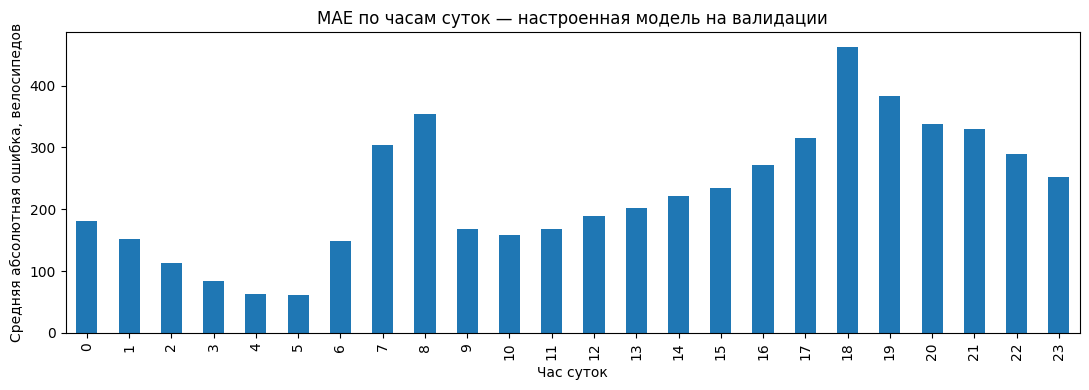

In [35]:
validation_errors = pd.DataFrame({
    "hour": val_data["Hour"].to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": tuned_val_pred,
})
validation_errors["abs_error"] = (
    validation_errors["actual"] - validation_errors["predicted"]
).abs()

hour_mae = validation_errors.groupby("hour")["abs_error"].mean()
plt.figure(figsize=(11, 4))
hour_mae.plot(kind="bar")
plt.title("MAE по часам суток — настроенная модель на валидации")
plt.xlabel("Час суток")
plt.ylabel("Средняя абсолютная ошибка, велосипедов")
plt.tight_layout()
plt.show()

## 14. Сравнение результатов RandomizedSearchCV и GridSearchCV

In [36]:

# Получаем лучшую модель после GridSearchCV
grid_model = grid_search.best_estimator_

# Делаем прогноз на валидационной выборке
grid_val_pred = np.maximum(grid_model.predict(X_val), 0)

# Рассчитываем метрики качества
grid_metrics = regression_metrics(y_val, grid_val_pred)

# Создаём общую таблицу сравнения трёх моделей
results = pd.DataFrame([
    {"Модель": "Без тюнинга", **base_metrics},
    {"Модель": "RandomizedSearchCV", **tuned_metrics},
    {"Модель": "GridSearchCV", **grid_metrics}
])

# Выводим результаты
print("Сравнение моделей на валидационной выборке:")
display(results.set_index("Модель").round(2))

# Определяем лучший метод по RMSE на валидации
best_result = results.loc[results["RMSE"].idxmin()]

print("\nЛучший результат на валидации:")
print(f"Модель: {best_result['Модель']}")
print(f"RMSE: {best_result['RMSE']:.2f}")


Сравнение моделей на валидационной выборке:


,RMSE,MAE,R2
Модель,,,
Без тюнинга,376.00,233.71,0.72
RandomizedSearchCV,349.90,227.07,0.76
GridSearchCV,377.05,235.84,0.72



Лучший результат на валидации:
Модель: RandomizedSearchCV
RMSE: 349.90


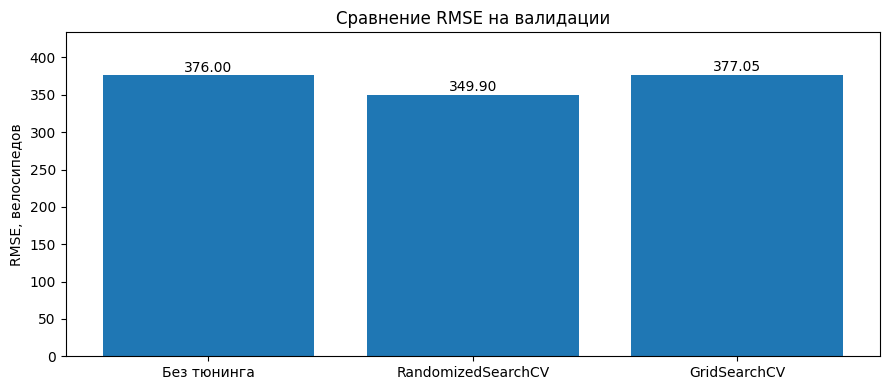

In [37]:

# Сравнение RMSE трёх моделей на валидации
plt.figure(figsize=(9, 4))

bars = plt.bar(results["Модель"], results["RMSE"])

plt.title("Сравнение RMSE на валидации")
plt.ylabel("RMSE, велосипедов")
plt.ylim(0, results["RMSE"].max() * 1.15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        f"{height:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


## 15. Проверка переобучения после GridSearchCV


In [39]:

# Получаем прогноз GridSearchCV на обучающих данных
grid_train_pred = np.maximum(
    grid_model.predict(X_train), 0
)

# Рассчитываем метрики на обучающей выборке
grid_train_metrics = regression_metrics(
    y_train, grid_train_pred
)

# Сравниваем качество на обучении и валидации
print("GridSearchCV — проверка переобучения")

print(
    f"RMSE на обучении: {grid_train_metrics['RMSE']:.2f}"
)

print(
    f"RMSE на валидации: {grid_metrics['RMSE']:.2f}"
)

# Вычисляем разницу ошибок
difference = (
    grid_metrics["RMSE"] - grid_train_metrics["RMSE"]
)

print(f"Разница RMSE: {difference:.2f}")


GridSearchCV — проверка переобучения
RMSE на обучении: 78.03
RMSE на валидации: 377.05
Разница RMSE: 299.02


In [17]:

# Сравниваем среднюю ошибку и разброс по фолдам
for name, model_search in [
    ("RandomizedSearchCV", search),
    ("GridSearchCV", grid_search)
]:
    idx = model_search.best_index_
    mean_rmse = -model_search.cv_results_["mean_test_score"][idx]
    std_rmse = model_search.cv_results_["std_test_score"][idx]

    print(f"{name}:")
    print(f"Средний RMSE: {mean_rmse:.2f}")
    print(f"Разброс (std): {std_rmse:.2f}")
    print()


RandomizedSearchCV:
Средний RMSE: 343.03
Разброс (std): 127.29

GridSearchCV:
Средний RMSE: 335.69
Разброс (std): 117.06



## 16. Итоговые выводы по подбору гиперпараметров

В рамках работы проведён подбор гиперпараметров модели RandomForestRegressor двумя методами: RandomizedSearchCV и GridSearchCV. Для оценки использовалась временная кросс-валидация TimeSeriesSplit с четырьмя фолдами и gap=24.

RandomizedSearchCV проверил 6 комбинаций параметров, GridSearchCV — 16 комбинаций.

Средний RMSE по четырём фолдам временной кросс-валидации составил **343,03 ± 127,29** для RandomizedSearchCV и **335,69 ± 117,06** для GridSearchCV (среднее ± стандартное отклонение).

Несмотря на более низкую среднюю ошибку GridSearchCV, оба метода показали значительный разброс результатов между временными фолдами. Это свидетельствует о нестабильности качества прогнозирования на разных временных интервалах. Одной из возможных причин являются сезонные изменения спроса на прокат велосипедов.

На отдельной валидационной выборке получены следующие результаты:

- Исходная модель: RMSE = 376,00; MAE = 233,71; R² = 0,723.
- RandomizedSearchCV: RMSE = 349,90; MAE = 227,07; R² = 0,761.
- GridSearchCV: RMSE = 377,05; MAE = 235,84; R² ≈ 0,72.

Наилучший результат на валидации показала модель, настроенная через RandomizedSearchCV: RMSE уменьшился на 6,94% относительно исходной модели.

Несмотря на более низкий средний RMSE GridSearchCV на кросс-валидации, качество этой модели на отдельной валидации оказалось хуже. Это показывает, что результаты кросс-валидации не гарантируют аналогичного качества на другом временном периоде. Поскольку методы проверяли разные наборы и количество комбинаций, нельзя делать общий вывод о превосходстве одного алгоритма поиска над другим.

У обеих настроенных моделей наблюдается значительный разрыв между ошибками на обучающей и валидационной выборках. Это может указывать на переобучение и/или различия временных периодов.

Результаты эксперимента предварительные: используется демонстрационная модель Random Forest и временное разделение данных 70/15/15. Для финального сравнения необходимо согласовать общие данные, признаки и схему валидации с командой. Тестовая выборка не использовалась.